In [1]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

In [2]:
file_path = r"/content/WA_Fn-UseC_-Telco-Customer-Churn.csv"

In [3]:
df = pd.read_csv(file_path)

In [4]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.drop(columns=["customerID"], inplace=True)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


In [7]:
df.isna().sum()

,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0
OnlineBackup,0


In [8]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

df["TotalCharges"].fillna(df["TotalCharges"].median(), inplace=True)

df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

/tmp/ipykernel_9429/1633905658.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["TotalCharges"].fillna(df["TotalCharges"].median(), inplace=True)


In [9]:
df.duplicated().sum()

np.int64(22)

In [10]:
df.drop_duplicates(inplace=True)

In [11]:
df["Churn"].value_counts()

,count
Churn,
0,5164
1,1857


In [12]:
categorical_cols = df.select_dtypes(include=["object"]).columns.tolist()
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

In [13]:
df["Churn"]

,Churn
0,0
1,0
2,1
3,0
4,1
...,...
7038,0
7039,0
7040,0
7041,1


In [14]:
X = df_encoded.drop(columns="Churn")
y = df_encoded["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

In [15]:
Model=DecisionTreeClassifier(
    criterion='entropy',
    splitter='best',
    max_depth=5,
    min_samples_split=3,
    min_samples_leaf=1,
    random_state=32,
)
Model.fit(X_train, y_train)
y_pred = Model.predict(X_test)

acc = accuracy_score(y_test, y_pred)
print(f"Accuracy : {acc}")

print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=["No Churn", "Churn"]))
print("\n")

Accuracy : 0.7879003558718861
Classification Report:
              precision    recall  f1-score   support

    No Churn       0.83      0.90      0.86      1033
       Churn       0.63      0.49      0.55       372

    accuracy                           0.79      1405
   macro avg       0.73      0.69      0.71      1405
weighted avg       0.78      0.79      0.78      1405





In [16]:
rf_model = RandomForestClassifier(
    n_estimators=400,
    max_depth=16,
    criterion="entropy",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)


rf_model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', criterion='entropy',
                       max_depth=16, n_estimators=400, n_jobs=-1,
                       random_state=42)

In [17]:
rf_pred=rf_model.predict(X_test)

acc = accuracy_score(y_test, rf_pred)
print(f"Accuracy : {acc}")

print("Classification Report:")
print(classification_report(y_test, rf_pred, target_names=["No Churn", "Churn"]))

Accuracy : 0.7900355871886121
Classification Report:
              precision    recall  f1-score   support

    No Churn       0.84      0.88      0.86      1033
       Churn       0.62      0.53      0.57       372

    accuracy                           0.79      1405
   macro avg       0.73      0.71      0.72      1405
weighted avg       0.78      0.79      0.78      1405



In [18]:
Model_SVC=SVC(
    C=5.0,
    kernel='rbf',
    gamma='auto')

Model_SVC.fit(X_train, y_train)
y_pred = Model_SVC.predict(X_test)

acc = accuracy_score(y_test, y_pred)
print(f"Accuracy : {acc}")

Accuracy : 0.7551601423487544


In [19]:
import matplotlib.pyplot as plt

In [20]:
# plt.figure(figsize=(10, 6))
# df_melted = df_results.reset_index().melt(id_vars='Model', var_name='Metric', value_name='Score')

# ax = sns.barplot(data=df_melted, x='Metric', y='Score', hue='Model', palette='Set2')
# plt.title("", fontsize=14, fontweight='bold')
# plt.ylim(0, 1.0)
# plt.ylabel(' (Score)')
# plt.grid(axis='y', linestyle='--', alpha=0.5)

# for p in ax.patches:
#     if p.get_height() > 0:
#         ax.annotate(f'{p.get_height():.2f}',
#                     (p.get_x() + p.get_width() / 2., p.get_height()),
#                     ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontsize=9)

# plt.legend(title='Model', bbox_to_anchor=(1.02, 1), loc='upper left')
# plt.tight_layout()
# plt.show()

In [21]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset

In [22]:

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [23]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_recall_fscore_support,
)
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.models import Sequential

In [24]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

input_dim = X_train_scaled.shape[1]

dl_model = Sequential(
    [
        Dense(128, activation="relu", input_shape=(input_dim,)),
        Dropout(0.3),
        Dense(64, activation="relu"),
        Dropout(0.2),
        Dense(32, activation="relu"),
        Dense(1, activation="sigmoid"),
    ]
)

dl_model.compile(
    optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"]
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [25]:
dl_model.summary()

from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = dl_model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32,

    callbacks=[early_stopping],
    verbose=1
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         3,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,337 (56.00 KB)

 Trainable params: 14,337 (56.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 7s 28ms/step - accuracy: 0.7658 - loss: 0.4696 - val_accuracy: 0.7954 - val_loss: 0.4427
Epoch 2/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7974 - loss: 0.4276 - val_accuracy: 0.7909 - val_loss: 0.4385
Epoch 3/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8010 - loss: 0.4218 - val_accuracy: 0.7883 - val_loss: 0.4416
Epoch 4/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8063 - loss: 0.4159 - val_accuracy: 0.7945 - val_loss: 0.4351
Epoch 5/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8090 - loss: 0.4163 - val_accuracy: 0.7927 - val_loss: 0.4307
Epoch 6/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8054 - loss: 0.4101 - val_accuracy: 0.7972 - val_loss: 0.4373
Epoch 7/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8110 - loss: 0.4041 - val_accuracy: 0.7980 - val_loss: 0.4417
Epoch 8/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8085 - loss: 0.4061 - val_accuracy: 0

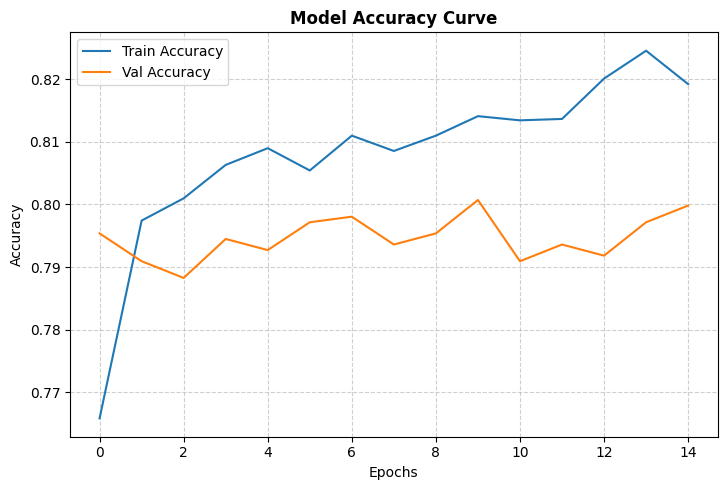

In [26]:
plt.figure(figsize=(14, 5))


plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Val Accuracy")
plt.title("Model Accuracy Curve", fontsize=12, fontweight="bold")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step

--- Model Comparison Summary ---
              Model  Accuracy  Precision   Recall  F1-Score
      Decision Tree  0.755160   0.561404 0.344086  0.426667
      Random Forest  0.790036   0.620690 0.532258  0.573082
                SVC  0.755160   0.561404 0.344086  0.426667
Deep Learning (MLP)  0.797865   0.653846 0.502688  0.568389


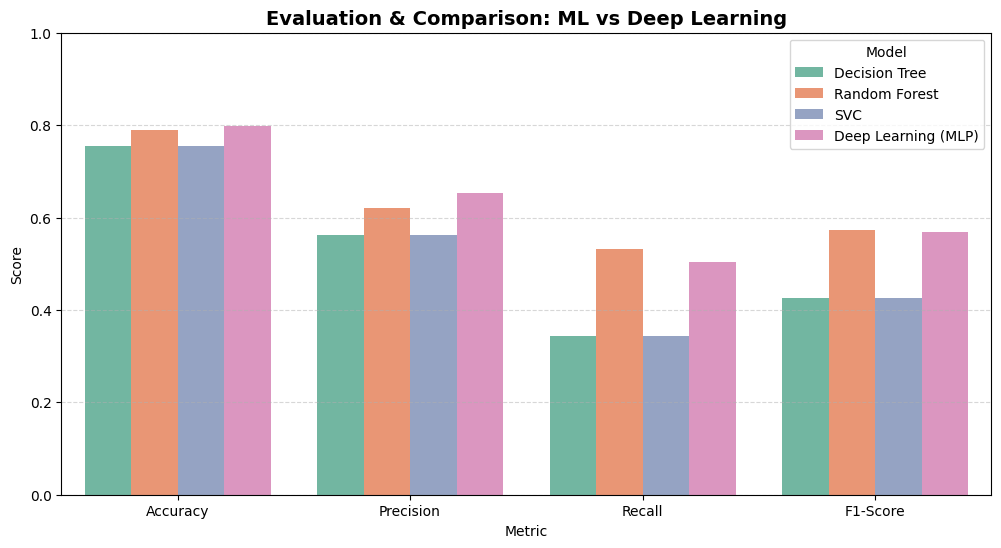

In [27]:
y_pred_dl_prob = dl_model.predict(X_test_scaled)
y_pred_dl = (y_pred_dl_prob > 0.5).astype(int).reshape(-1)

models = {
    "Decision Tree": y_pred,
    "Random Forest": rf_pred,
    "SVC": Model_SVC.predict(X_test),
    "Deep Learning (MLP)": y_pred_dl,
}

results = []

for name, preds in models.items():
    acc = accuracy_score(y_test, preds)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test, preds, average="binary", pos_label=1
    )
    results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
    })

df_results = pd.DataFrame(results)
print("\n--- Model Comparison Summary ---")
print(df_results.to_string(index=False))

plt.figure(figsize=(12, 6))
df_melted = df_results.melt(
    id_vars="Model", var_name="Metric", value_name="Score"
)

ax = sns.barplot(
    data=df_melted, x="Metric", y="Score", hue="Model", palette="Set2"
)
plt.title("Evaluation & Comparison: ML vs Deep Learning", fontsize=14, fontweight="bold")
plt.ylim(0, 1.0)
plt.ylabel("Score")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

### 🔮 Interactive Customer Churn Predictor
Adjust the customer's attributes using the Form panel on the right, then run this cell to instantly obtain prediction results from all trained models.

In [46]:
# @title 🛠️ Customer Data Input & Prediction Form

tenure = 1  # @param {type:"slider", min:1, max:72, step:1}
MonthlyCharges = 20  # @param {type:"number"}
TotalCharges = 100  # @param {type:"number"}
gender = "Male"  # @param ["Female", "Male"]
SeniorCitizen = "No"  # @param ["No", "Yes"]
Partner = "No"  # @param ["No", "Yes"]
Dependents = "Yes"  # @param ["No", "Yes"]
PhoneService = "Yes"  # @param ["No", "Yes"]
MultipleLines = "No"  # @param ["No", "Yes", "No phone service"]
InternetService = "Fiber optic"  # @param ["DSL", "Fiber optic", "No"]
OnlineSecurity = "No"  # @param ["No", "Yes", "No internet service"]
OnlineBackup = "No"  # @param ["No", "Yes", "No internet service"]
DeviceProtection = "No"  # @param ["No", "Yes", "No internet service"]
TechSupport = "No"  # @param ["No", "Yes", "No internet service"]
StreamingTV = "Yes"  # @param ["No", "Yes", "No internet service"]
StreamingMovies = "Yes"  # @param ["No", "Yes", "No internet service"]
Contract = "Month-to-month"  # @param ["Month-to-month", "One year", "Two year"]
PaperlessBilling = "Yes"  # @param ["No", "Yes"]
PaymentMethod = "Mailed check"  # @param ["Bank transfer (automatic)", "Credit card (automatic)", "Electronic check", "Mailed check"]

# 1. Initialize a DataFrame with 0 matching the model features
custom_input = pd.DataFrame(0, index=[0], columns=X.columns)

# 2. Assign numeric values
custom_input["tenure"] = tenure
custom_input["MonthlyCharges"] = MonthlyCharges
custom_input["TotalCharges"] = TotalCharges
custom_input["SeniorCitizen"] = 1 if SeniorCitizen == "Yes" else 0

# 3. Assign categorical values (One-Hot Encoded variables)
if gender == "Male": custom_input["gender_Male"] = 1
if Partner == "Yes": custom_input["Partner_Yes"] = 1
if Dependents == "Yes": custom_input["Dependents_Yes"] = 1
if PhoneService == "Yes": custom_input["PhoneService_Yes"] = 1

if MultipleLines == "No phone service": custom_input["MultipleLines_No phone service"] = 1
elif MultipleLines == "Yes": custom_input["MultipleLines_Yes"] = 1

if InternetService == "Fiber optic": custom_input["InternetService_Fiber optic"] = 1
elif InternetService == "No": custom_input["InternetService_No"] = 1

if OnlineSecurity == "No internet service": custom_input["OnlineSecurity_No internet service"] = 1
elif OnlineSecurity == "Yes": custom_input["OnlineSecurity_Yes"] = 1

if OnlineBackup == "No internet service": custom_input["OnlineBackup_No internet service"] = 1
elif OnlineBackup == "Yes": custom_input["OnlineBackup_Yes"] = 1

if DeviceProtection == "No internet service": custom_input["DeviceProtection_No internet service"] = 1
elif DeviceProtection == "Yes": custom_input["DeviceProtection_Yes"] = 1

if TechSupport == "No internet service": custom_input["TechSupport_No internet service"] = 1
elif TechSupport == "Yes": custom_input["TechSupport_Yes"] = 1

if StreamingTV == "No internet service": custom_input["StreamingTV_No internet service"] = 1
elif StreamingTV == "Yes": custom_input["StreamingTV_Yes"] = 1

if StreamingMovies == "No internet service": custom_input["StreamingMovies_No internet service"] = 1
elif StreamingMovies == "Yes": custom_input["StreamingMovies_Yes"] = 1

if Contract == "One year": custom_input["Contract_One year"] = 1
elif Contract == "Two year": custom_input["Contract_Two year"] = 1

if PaperlessBilling == "Yes": custom_input["PaperlessBilling_Yes"] = 1

if PaymentMethod == "Credit card (automatic)": custom_input["PaymentMethod_Credit card (automatic)"] = 1
elif PaymentMethod == "Electronic check": custom_input["PaymentMethod_Electronic check"] = 1
elif PaymentMethod == "Mailed check": custom_input["PaymentMethod_Mailed check"] = 1

# 4. Standard scale inputs for models requiring scaled variables (SVC & MLP)
custom_input_scaled = scaler.transform(custom_input)

# 5. Get predictions
pred_dt = Model.predict(custom_input)[0]
pred_rf = rf_model.predict(custom_input)[0]
pred_svc = Model_SVC.predict(custom_input_scaled)[0]
pred_dl_prob = dl_model.predict(custom_input_scaled, verbose=0)[0][0]
pred_dl = 1 if pred_dl_prob > 0.5 else 0

# Formatting helper
def format_result(val, prob=None):
    if val == 1:
        prob_str = f" (Probability: {prob:.1%})" if prob is not None else ""
        return f"🔴 Churn{prob_str}"
    else:
        prob_str = f" (Probability: {1-prob:.1%})" if prob is not None else ""
        return f"🟢 No Churn{prob_str}"

# 6. Print clean results for all models
print("\n" + "="*65)
print("                     📊 MODEL PREDICTION RESULTS 📊                     ")
print("="*65)
print(f"  • Decision Tree    : {format_result(pred_dt)}")
print(f"  • Random Forest    : {format_result(pred_rf)}")
print(f"  • SVM Classifier   : {format_result(pred_svc)}")
print(f"  • Deep Learning    : {format_result(pred_dl, pred_dl_prob)}")
print("="*65)


                     📊 MODEL PREDICTION RESULTS 📊                     
  • Decision Tree    : 🔴 Churn
  • Random Forest    : 🔴 Churn
  • SVM Classifier   : 🟢 No Churn
  • Deep Learning    : 🔴 Churn (Probability: 64.5%)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


In [47]:
%%sh
pip install streamlit -q
npm install -g localtunnel -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 105.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 109.6 MB/s eta 0:00:00

added 22 packages in 2s

3 packages are looking for funding
  run `npm fund` for details


In [48]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import joblib
import tensorflow as tf
# Re-importing or using globally loaded variables isn't guaranteed in independent python runs,
# so in a real app you would load saved models.
# For this notebook context, we can fetch them from the notebook's active namespace if we run inside Colab,
# but since Streamlit runs as a separate process, we should save the models to disk first so app.py can load them.


Writing app.py


In [49]:
# حفظ الموديلات الحالية على القرص حتى يتمكن تطبيق Streamlit من قراءتها بشكل صحيح
import joblib
joblib.dump(Model, 'decision_tree_model.pkl')
joblib.dump(rf_model, 'random_forest_model.pkl')
joblib.dump(Model_SVC, 'svc_model.pkl')
joblib.dump(scaler, 'scaler.pkl')
dl_model.save('dl_model.keras')
print("Saved all models to disk successfully!")

Saved all models to disk successfully!


In [50]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import joblib
import tensorflow as tf

# 1. Load models
@st.cache_resource
def load_resources():
    dt = joblib.load('decision_tree_model.pkl')
    rf = joblib.load('random_forest_model.pkl')
    svc = joblib.load('svc_model.pkl')
    scaler = joblib.load('scaler.pkl')
    dl = tf.keras.models.load_model('dl_model.keras')
    return dt, rf, svc, scaler, dl

try:
    dt, rf, svc, scaler, dl = load_resources()
    st.success("Models loaded successfully!")
except Exception as e:
    st.error(f"Error loading models: {e}")

st.title("🔮 Telco Customer Churn Predictor")
st.write("Adjust client details to predict churn risk across multiple models.")

# Sidebar/Inputs
tenure = st.sidebar.slider("Tenure (months)", 1, 72, 12)
MonthlyCharges = st.sidebar.number_input("Monthly Charges ($)", value=50.0)
TotalCharges = st.sidebar.number_input("Total Charges ($)", value=500.0)
gender = st.sidebar.selectbox("Gender", ["Female", "Male"])
SeniorCitizen = st.sidebar.selectbox("Senior Citizen", ["No", "Yes"])
Partner = st.sidebar.selectbox("Partner", ["No", "Yes"])
Dependents = st.sidebar.selectbox("Dependents", ["No", "Yes"])
PhoneService = st.sidebar.selectbox("Phone Service", ["No", "Yes"])
MultipleLines = st.sidebar.selectbox("Multiple Lines", ["No", "Yes", "No phone service"])
InternetService = st.sidebar.selectbox("Internet Service", ["DSL", "Fiber optic", "No"])
OnlineSecurity = st.sidebar.selectbox("Online Security", ["No", "Yes", "No internet service"])
OnlineBackup = st.sidebar.selectbox("Online Backup", ["No", "Yes", "No internet service"])
DeviceProtection = st.sidebar.selectbox("Device Protection", ["No", "Yes", "No internet service"])
TechSupport = st.sidebar.selectbox("Tech Support", ["No", "Yes", "No internet service"])
StreamingTV = st.sidebar.selectbox("Streaming TV", ["No", "Yes", "No internet service"])
StreamingMovies = st.sidebar.selectbox("Streaming Movies", ["No", "Yes", "No internet service"])
Contract = st.sidebar.selectbox("Contract", ["Month-to-month", "One year", "Two year"])
PaperlessBilling = st.sidebar.selectbox("Paperless Billing", ["No", "Yes"])
PaymentMethod = st.sidebar.selectbox("Payment Method", ["Bank transfer (automatic)", "Credit card (automatic)", "Electronic check", "Mailed check"])

# Feature preparation
# Hardcoded model features based on X.columns structure
features_list = [
    'SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges',
    'gender_Male', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes',
    'MultipleLines_No phone service', 'MultipleLines_Yes',
    'InternetService_Fiber optic', 'InternetService_No',
    'OnlineSecurity_No internet service', 'OnlineSecurity_Yes',
    'OnlineBackup_No internet service', 'OnlineBackup_Yes',
    'DeviceProtection_No internet service', 'DeviceProtection_Yes',
    'TechSupport_No internet service', 'TechSupport_Yes',
    'StreamingTV_No internet service', 'StreamingTV_Yes',
    'StreamingMovies_No internet service', 'StreamingMovies_Yes',
    'Contract_One year', 'Contract_Two year', 'PaperlessBilling_Yes',
    'PaymentMethod_Credit card (automatic)',
    'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check'
]

custom_input = pd.DataFrame(0, index=[0], columns=features_list)

custom_input["tenure"] = tenure
custom_input["MonthlyCharges"] = MonthlyCharges
custom_input["TotalCharges"] = TotalCharges
custom_input["SeniorCitizen"] = 1 if SeniorCitizen == "Yes" else 0

if gender == "Male": custom_input["gender_Male"] = 1
if Partner == "Yes": custom_input["Partner_Yes"] = 1
if Dependents == "Yes": custom_input["Dependents_Yes"] = 1
if PhoneService == "Yes": custom_input["PhoneService_Yes"] = 1
if MultipleLines == "No phone service": custom_input["MultipleLines_No phone service"] = 1
elif MultipleLines == "Yes": custom_input["MultipleLines_Yes"] = 1
if InternetService == "Fiber optic": custom_input["InternetService_Fiber optic"] = 1
elif InternetService == "No": custom_input["InternetService_No"] = 1
if OnlineSecurity == "No internet service": custom_input["OnlineSecurity_No internet service"] = 1
elif OnlineSecurity == "Yes": custom_input["OnlineSecurity_Yes"] = 1
if OnlineBackup == "No internet service": custom_input["OnlineBackup_No internet service"] = 1
elif OnlineBackup == "Yes": custom_input["OnlineBackup_Yes"] = 1
if DeviceProtection == "No internet service": custom_input["DeviceProtection_No internet service"] = 1
elif DeviceProtection == "Yes": custom_input["DeviceProtection_Yes"] = 1
if TechSupport == "No internet service": custom_input["TechSupport_No internet service"] = 1
elif TechSupport == "Yes": custom_input["TechSupport_Yes"] = 1
if StreamingTV == "No internet service": custom_input["StreamingTV_No internet service"] = 1
elif StreamingTV == "Yes": custom_input["StreamingTV_Yes"] = 1
if StreamingMovies == "No internet service": custom_input["StreamingMovies_No internet service"] = 1
elif StreamingMovies == "Yes": custom_input["StreamingMovies_Yes"] = 1
if Contract == "One year": custom_input["Contract_One year"] = 1
elif Contract == "Two year": custom_input["Contract_Two year"] = 1
if PaperlessBilling == "Yes": custom_input["PaperlessBilling_Yes"] = 1
if PaymentMethod == "Credit card (automatic)": custom_input["PaymentMethod_Credit card (automatic)"] = 1
elif PaymentMethod == "Electronic check": custom_input["PaymentMethod_Electronic check"] = 1
elif PaymentMethod == "Mailed check": custom_input["PaymentMethod_Mailed check"] = 1

custom_input_scaled = scaler.transform(custom_input)

# Predict buttons
if st.button("Predict Churn"):
    pred_dt = dt.predict(custom_input)[0]
    pred_rf = rf.predict(custom_input)[0]
    pred_svc = svc.predict(custom_input_scaled)[0]
    pred_dl_prob = dl.predict(custom_input_scaled, verbose=0)[0][0]
    pred_dl = 1 if pred_dl_prob > 0.5 else 0

    def show(val, prob=None):
        if val == 1:
            return f"🔴 Churn" + (f" ({prob:.1%})" if prob is not None else "")
        return f"🟢 No Churn" + (f" ({1-prob:.1%})" if prob is not None else "")

    st.subheader("Results:")
    col1, col2 = st.columns(2)
    with col1:
        st.metric("Decision Tree", show(pred_dt))
        st.metric("SVM Classifier", show(pred_svc))
    with col2:
        st.metric("Random Forest", show(pred_rf))
        st.metric("Deep Learning", show(pred_dl, pred_dl_prob))


Overwriting app.py


In [ ]:
# تشغيل التطبيق في الخلفية والحصول على رابط Tunnel
import urllib
print("Your public IP address for Tunnel connection:")
!curl ipv4.icanhazip.com
print("\nClick on the link below, insert the IP above, and start testing your Streamlit app:")
!streamlit run app.py & npx localtunnel --port 8501

Your public IP address for Tunnel connection:
34.7.175.183

Click on the link below, insert the IP above, and start testing your Streamlit app:
⠙⠹⠸⠼⠴⠦⠧⠇⠏

your url is: https://clean-weeks-lie.loca.lt
2026-10-05 10:44:35.645 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.7.175.183:8501

2026-10-05 10:46:12.610355: W tensorflow/core/common_runtime/gpu/gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was 0.
I0000 00:00:1791197172.611877   13574 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13379 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SVC 

In [29]:
df_encoded.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7021 entries, 0 to 7042
Data columns (total 31 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   SeniorCitizen                          7021 non-null   int64  
 1   tenure                                 7021 non-null   int64  
 2   MonthlyCharges                         7021 non-null   float64
 3   TotalCharges                           7021 non-null   float64
 4   Churn                                  7021 non-null   int64  
 5   gender_Male                            7021 non-null   bool   
 6   Partner_Yes                            7021 non-null   bool   
 7   Dependents_Yes                         7021 non-null   bool   
 8   PhoneService_Yes                       7021 non-null   bool   
 9   MultipleLines_No phone service         7021 non-null   bool   
 10  MultipleLines_Yes                      7021 non-null   bool   
 11  InternetS